# Этап 3. Часть 1 - Анализ данных

**Датасет:** Students Performance in Exams (Kaggle, автор spscientist)

**План:**
1. Загрузка и очистка данных (дубликаты, пропуски, логические ошибки)
2. Выборка 25% датасета для анализа
3. Графики по признакам
4. Среднее и медиана
5. Гипотезы: ход мыслей и проверка на оставшихся 75%
6. Вывод

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## 1. Загрузка и очистка данных

Сначала загружаю исходный файл. Если ноутбук запущен из папки репозитория, берётся локальный файл, иначе (например, в Colab) - файл с GitHub.

In [2]:
RAW_PATH = '../data/raw/StudentsPerformance.csv'
RAW_URL = 'https://raw.githubusercontent.com/arsenijchekin-a11y/icp-students-performance/main/data/raw/StudentsPerformance.csv'

if os.path.exists(RAW_PATH):
    source = RAW_PATH
else:
    source = RAW_URL

df = pd.read_csv(source, sep=None, engine='python')
print('Исходный размер:', df.shape)

Исходный размер: (1000, 8)


Переименовываю столбцы, чтобы с ними было удобнее работать в коде (без пробелов и `/`).

In [3]:
df = df.rename(columns={
    'race/ethnicity': 'race_ethnicity',
    'parental level of education': 'parent_education',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
})

score_cols = ['math_score', 'reading_score', 'writing_score']
cat_cols = ['gender', 'race_ethnicity', 'parent_education', 'lunch', 'test_prep']

### 1.1. Дубликаты

Полностью одинаковые строки удаляю, оставляя первую. Важная оговорка: в датасете нет ID ученика, поэтому две одинаковые строки теоретически могут быть разными учениками. Но совпадение по всем 8 полям, включая три оценки, маловероятно, поэтому такие строки считаю повторной записью.

In [4]:
dups = df.duplicated().sum()
print('Полных дубликатов:', dups)
df = df.drop_duplicates()

Полных дубликатов: 0


### 1.2. Пропуски

Проверяю обычные пропуски (NaN) и текстовые маркеры, которыми иногда обозначают отсутствие значения. Строки с пропусками удаляю, а не заполняю: заполнение средним или модой искажает зависимости между признаками, а именно их мы будем проверять в гипотезах.

Значение `none` в столбце `test_prep` - не пропуск, а категория «не проходил курс», поэтому его не трогаю.

In [5]:
markers = ['', 'nan', 'NaN', 'NA', 'N/A', '-', '?', 'нет данных']

# убираем лишние пробелы в текстовых столбцах и заменяем маркеры на NaN
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace(markers, np.nan)

print('Пропусков по столбцам:')
print(df.isna().sum())

df = df.dropna()

Пропусков по столбцам:
gender              0
race_ethnicity      0
parent_education    0
lunch               0
test_prep           0
math_score          0
reading_score       0
writing_score       0
dtype: int64


### 1.3. Логические ошибки

Проверяю правила из Этапа 2:
- оценки должны быть числами от 0 до 100;
- категориальные признаки должны принимать только допустимые значения.

Строки, нарушающие правила, удаляю - исправить их без источника нельзя.

In [6]:
allowed = {
    'gender': ['female', 'male'],
    'race_ethnicity': ['group A', 'group B', 'group C', 'group D', 'group E'],
    'parent_education': ['some high school', 'high school', 'some college',
                         "associate's degree", "bachelor's degree", "master's degree"],
    'lunch': ['standard', 'free/reduced'],
    'test_prep': ['none', 'completed']
}

bad = pd.Series(False, index=df.index)

for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    bad = bad | df[col].isna() | (df[col] < 0) | (df[col] > 100)

for col in cat_cols:
    bad = bad | ~df[col].isin(allowed[col])

print('Строк с логическими ошибками:', bad.sum())
df = df[~bad]

print('Размер после очистки:', df.shape)

Строк с логическими ошибками: 0
Размер после очистки: (1000, 8)


**Итог очистки:** дубликатов, пропусков и логических ошибок не найдено, все 1000 строк остались. Это совпадает с результатом аудита в Этапе 2. Выбросы (очень низкие оценки) не удаляю - в Этапе 2 показано, что они правдоподобны.

## 2. Выборка для анализа

Беру случайные 25% датасета (250 учеников). Случайный выбор лучше, чем «подряд»: если строки в файле упорядочены по какому-то признаку, выборка подряд окажется смещённой. `random_state=42` фиксирует случайность, чтобы результат повторялся при каждом запуске.

На этих 25% я смотрю на данные и формулирую гипотезы, а проверяю их на оставшихся 75%. Так гипотеза проверяется на данных, которые я не видел, когда её придумывал.

In [7]:
sample = df.sample(frac=0.25, random_state=42)
rest = df.drop(sample.index)

print('Выборка для анализа:', len(sample))
print('Оставшаяся часть для проверки:', len(rest))

Выборка для анализа: 250
Оставшаяся часть для проверки: 750


## 3. Графики по признакам

### График 1. Распределение оценки по математике

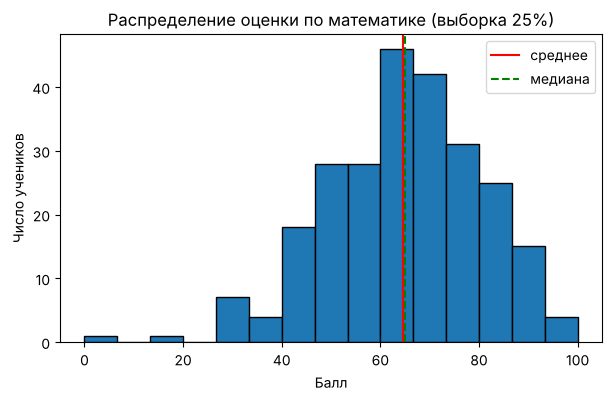

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(sample['math_score'], bins=15, edgecolor='black')
plt.axvline(sample['math_score'].mean(), color='red', label='среднее')
plt.axvline(sample['math_score'].median(), color='green', linestyle='--', label='медиана')
plt.title('Распределение оценки по математике (выборка 25%)')
plt.xlabel('Балл')
plt.ylabel('Число учеников')
plt.legend()
plt.show()

Распределение похоже на нормальное: большинство учеников набирают 50-80 баллов, среднее и медиана почти совпадают. Слева есть несколько очень низких оценок.

### График 2. Оценка по математике по группам: подготовка к экзамену и тип питания

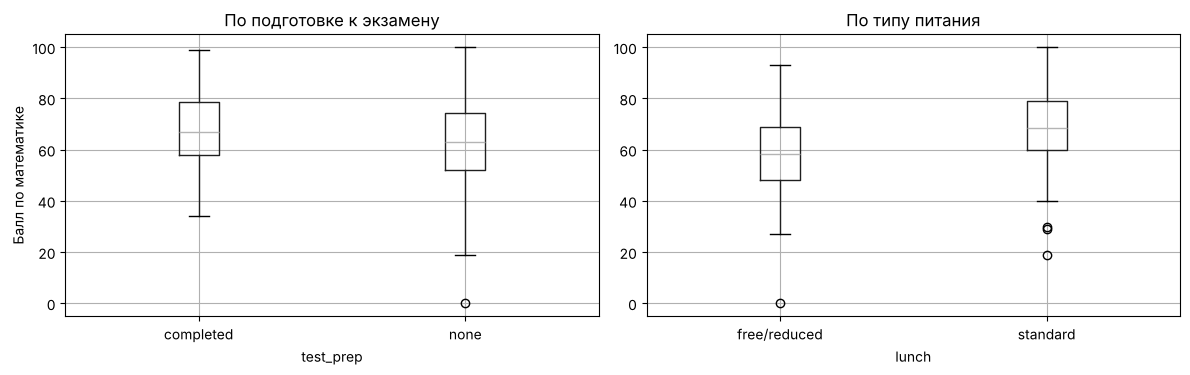

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sample.boxplot(column='math_score', by='test_prep', ax=axes[0])
axes[0].set_title('По подготовке к экзамену')
axes[0].set_xlabel('test_prep')
axes[0].set_ylabel('Балл по математике')

sample.boxplot(column='math_score', by='lunch', ax=axes[1])
axes[1].set_title('По типу питания')
axes[1].set_xlabel('lunch')

plt.suptitle('')
plt.tight_layout()
plt.show()

У прошедших подготовку и у учеников со стандартным питанием «ящик» сдвинут вверх - медиана выше.

### График 3. Средние оценки по предметам у мальчиков и девочек

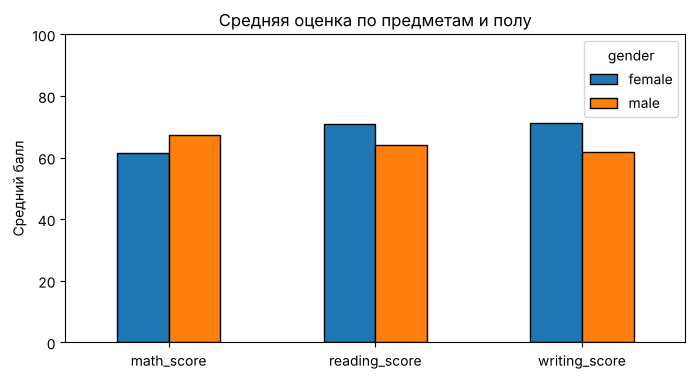

In [10]:
gender_means = sample.groupby('gender')[score_cols].mean()

gender_means.T.plot(kind='bar', figsize=(8, 4), edgecolor='black')
plt.title('Средняя оценка по предметам и полу')
plt.ylabel('Средний балл')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

Картина разная по предметам: в математике выше мальчики, а в чтении и письме - девочки.

## 4. Среднее и медиана

### 4.1. По числовым признакам

In [11]:
sample[score_cols].agg(['mean', 'median']).round(2)

,math_score,reading_score,writing_score
mean,64.55,67.4,66.21
median,65.00,68.5,68.50


Среднее и медиана близки у всех трёх оценок (разница 0.5-2 балла), то есть распределения почти симметричные. Медиана чуть выше среднего - это влияние низких выбросов, которые тянут среднее вниз.

### 4.2. По группам

In [12]:
for col in ['test_prep', 'lunch', 'gender']:
    print(col)
    print(sample.groupby(col)[score_cols].agg(['mean', 'median']).round(1))
    print()

test_prep
          math_score        reading_score        writing_score       
                mean median          mean median          mean median
test_prep                                                            
completed       67.7   67.0          72.5   75.0          72.9   75.0
none            62.7   63.0          64.3   65.0          62.2   64.0

lunch
             math_score        reading_score        writing_score       
                   mean median          mean median          mean median
lunch                                                                   
free/reduced       58.2   58.5          63.7   63.0          62.3   61.5
standard           68.3   68.5          69.6   72.0          68.6   70.0

gender
       math_score        reading_score        writing_score       
             mean median          mean median          mean median
gender                                                            
female       61.6   62.5          71.1   72.5          71.1

## 5. Гипотезы

Для проверки использую **t-тест Уэлча** (`ttest_ind` с `equal_var=False`): он сравнивает средние двух групп и не требует, чтобы разброс в группах был одинаковым. Группы большие (сотни учеников), поэтому t-тест применим даже при небольших отклонениях от нормальности.

Тест односторонний (`alternative='greater'`), потому что гипотезы направленные: «в группе А балл **выше**».

Уровень значимости - **0.05**: если p-value меньше 0.05, разница считается статистически значимой и гипотеза подтверждается.

Проверка идёт на **оставшихся 75%** (750 учеников), которые не использовались при формулировке гипотез.

In [13]:
def check(data, col, group_a, group_b, score):
    a = data[data[col] == group_a][score]
    b = data[data[col] == group_b][score]
    res = stats.ttest_ind(a, b, equal_var=False, alternative='greater')
    if res.pvalue < 0.05:
        verdict = 'подтверждается'
    else:
        verdict = 'не подтверждается'
    return {'Сравнение': f'{group_a} > {group_b}', 'Оценка': score,
            'Среднее A': round(a.mean(), 1), 'Среднее B': round(b.mean(), 1),
            't': round(res.statistic, 2), 'p-value': f'{res.pvalue:.2e}',
            'Вывод': verdict}

### Гипотеза 1. Подготовка к экзамену повышает баллы

**Ход мыслей:** на графике 2 у прошедших курс подготовки медиана по математике выше. В таблице средних разница видна по всем трём предметам: математика 67.7 против 62.7, чтение 72.5 против 64.3, письмо 72.9 против 62.2. Логично ожидать, что подготовка помогает на экзамене.

**H0:** средний балл у прошедших подготовку не выше, чем у не проходивших.
**H1:** средний балл у прошедших подготовку выше.

In [14]:
h1 = pd.DataFrame([check(rest, 'test_prep', 'completed', 'none', s) for s in score_cols])
h1

,Сравнение,Оценка,Среднее A,Среднее B,t,p-value,Вывод
0,completed > none,math_score,70.4,64.5,5.26,1.05e-07,подтверждается
1,completed > none,reading_score,74.4,67.2,6.78,1.59e-11,подтверждается
2,completed > none,writing_score,75.0,65.2,9.27,1.79e-19,подтверждается


**Результат:** по всем трём предметам p-value намного меньше 0.05, гипотеза подтверждается. Сильнее всего подготовка связана с письмом (разница около 10 баллов), слабее всего - с математикой (около 6 баллов).

### Гипотеза 2. Стандартное питание связано с более высокими баллами

**Ход мыслей:** тип питания `free/reduced` (бесплатное или льготное) обычно получают ученики из менее обеспеченных семей. На графике 2 медиана по математике у них заметно ниже, а в таблице средних разница около 10 баллов (68.3 против 58.2). Предполагаю, что материальное положение семьи связано с успеваемостью.

**H0:** средний балл при стандартном питании не выше, чем при льготном.
**H1:** средний балл при стандартном питании выше.

In [15]:
h2 = pd.DataFrame([check(rest, 'lunch', 'standard', 'free/reduced', s) for s in score_cols])
h2

,Сравнение,Оценка,Среднее A,Среднее B,t,p-value,Вывод
0,standard > free/reduced,math_score,70.6,59.2,10.39,2.64e-23,подтверждается
1,standard > free/reduced,reading_score,72.3,65.0,6.80,1.43e-11,подтверждается
2,standard > free/reduced,writing_score,71.5,63.3,7.42,2.50e-13,подтверждается


**Результат:** гипотеза подтверждается по всем предметам. Самая большая разница - по математике (около 11 баллов). Важно: это связь, а не причина - питание здесь скорее показатель достатка семьи, а не фактор, который сам влияет на оценки.

### Гипотеза 3. Мальчики лучше в математике, девочки - в чтении и письме

**Ход мыслей:** на графике 3 видно, что направление разницы зависит от предмета: по математике мальчики выше (67.3 против 61.6), а по чтению и письму выше девочки (71.1 против 64.0 и 71.1 против 61.7). Поэтому гипотеза составная, и каждую часть проверяю отдельно, в своём направлении.

**H1 (математика):** у мальчиков средний балл выше.
**H1 (чтение, письмо):** у девочек средний балл выше.

In [16]:
h3 = pd.DataFrame([
    check(rest, 'gender', 'male', 'female', 'math_score'),
    check(rest, 'gender', 'female', 'male', 'reading_score'),
    check(rest, 'gender', 'female', 'male', 'writing_score')
])
h3

,Сравнение,Оценка,Среднее A,Среднее B,t,p-value,Вывод
0,male > female,math_score,69.3,64.3,4.65,1.94e-06,подтверждается
1,female > male,reading_score,73.1,66.0,6.97,3.46e-12,подтверждается
2,female > male,writing_score,72.9,63.9,8.68,1.25e-17,подтверждается


**Результат:** все три части подтверждаются: у мальчиков выше математика (примерно на 5 баллов), у девочек - чтение (на 7) и письмо (на 9).

## 6. Вывод

1. **Очистка:** дубликатов, пропусков и логических ошибок в датасете нет, все 1000 строк пригодны для анализа.
2. **Описательная статистика:** средние оценки - около 65-67 баллов, среднее и медиана почти совпадают, распределения близки к нормальному, с небольшим числом низких выбросов.
3. **Гипотезы:** все три гипотезы, сформулированные на 25% данных, подтвердились на оставшихся 75%:
   - прошедшие подготовку к экзамену получают больше баллов по всем предметам;
   - ученики со стандартным питанием получают больше баллов, сильнее всего - по математике;
   - мальчики в среднем лучше в математике, девочки - в чтении и письме.
4. **Значение для модели:** признаки `test_prep`, `lunch` и `gender` статистически связаны с оценкой по математике, поэтому их стоит использовать как признаки модели в следующих этапах.
5. **Ограничение:** t-тест показывает связь, но не причину. Кроме того, датасет, вероятно, синтетический, поэтому выводы нельзя напрямую переносить на реальных школьников.